In [1]:
import torch
from reasoning_from_scratch.ch02 import get_device
from reasoning_from_scratch.ch03 import (
     load_model_and_tokenizer
)

device = get_device()

model, tokenizer = load_model_and_tokenizer(
    which_model="base",
    device=device,
    use_compile=False,
    local_dir="/Users/david.solanas/Documents/ai/reasoning-model-from-scratch/models/qwen3"
)

Using Apple Silicon GPU (MPS)
✓ /Users/david.solanas/Documents/ai/reasoning-model-from-scratch/models/qwen3/qwen3-0.6B-base.pth already up-to-date


In [2]:
from rmfs.prompts import render_prompt

raw_prompt = (
    "Half the value of $3x-9$ is $x+37$. "
    "What is the value of $x$?"
)
prompt = render_prompt(raw_prompt)
print(prompt)

You are a helpful math assistant.
Answer the question and write the final result on a new line as:
\boxed{ANSWER}

Question:
Half the value of $3x-9$ is $x+37$. What is the value of $x$?

Answer:


In [3]:
from reasoning_from_scratch.qwen3 import Qwen3Model, Qwen3Tokenizer
from rmfs.generation.greedy import generate_text_basic_stream_cache


def generate_text_stream_concat_flex(
    model: Qwen3Model,
    tokenizer: Qwen3Tokenizer,
    prompt: str,
    device: torch.device,
    max_new_tokens: int | None,
    verbose: bool = False,
    generate_func = None, # We add parameters to accept a text generation function and additional args
    **generate_kwargs
):
    if generate_func is None:
        generate_func = generate_text_basic_stream_cache

    input_ids = torch.tensor(
        tokenizer.encode(prompt), device=device
    ).unsqueeze(0)

    generated_ids = []
    for token in generate_func(
        model=model,
        token_ids=input_ids,
        max_new_tokens=max_new_tokens,
        eos_token_id=tokenizer.eos_token_id,
        **generate_kwargs
    ):
        next_token_id = token.squeeze(0)
        generated_ids.append(next_token_id.item())

        if verbose:
            print(
                tokenizer.decode(next_token_id.tolist()),
                end="",
                flush=True
            )

    return tokenizer.decode(generated_ids)

In [4]:
response = generate_text_stream_concat_flex(
    model, tokenizer, prompt, device,
    max_new_tokens=2048, verbose=True,
    generate_func=generate_text_basic_stream_cache
)

 \boxed{20}

In [5]:
prompt_cot = prompt + " \n\nExplain step by step."

response_cot = generate_text_stream_concat_flex(
    model, tokenizer, prompt_cot, device,
    max_new_tokens=2048, verbose=True,
)

 To solve the problem, we need to find the value of \( x \) such that half the value of \( 3x - 9 \) is equal to \( x + 37 \).

### Step 1: Set up the equation
We are given that half the value of \( 3x - 9 \) is equal to \( x + 37 \). This can be written as:
\[
\frac{1}{2}(3x - 9) = x + 37
\]

### Step 2: Eliminate the fraction
To eliminate the fraction, multiply both sides of the equation by 2:
\[
2 \cdot \frac{1}{2}(3x - 9) = 2(x + 37)
\]
Simplifying both sides:
\[
3x - 9 = 2x + 74
\]

### Step 3: Solve for \( x \)
Subtract \( 2x \) from both sides to isolate \( x \):
\[
3x - 2x - 9 = 74
\]
Simplify:
\[
x - 9 = 74
\]
Add 9 to both sides to solve for \( x \):
\[
x = 74 + 9
\]
\[
x = 83
\]

### Final Answer:
\[
\boxed{83}
\]

In [6]:
ex_prompt = "The capital of Germany is"

response = generate_text_stream_concat_flex(
    model, tokenizer, ex_prompt, device,
    max_new_tokens=1, verbose=True
)

 Berlin

In [7]:
def scale_logits_by_temperature(logits, temperature):
    if temperature <= 0:
        raise ValueError("Temperature must be positive")
    return logits / temperature

def softmax_with_temperature(logits, temperature):
    scaled_logits = logits / temperature
    return torch.softmax(scaled_logits, dim=0)

def count_samples(probas, num_samples=1000, threshold=1, tokenizer=None):
    samples = torch.multinomial(  #1
        probas.cpu(), num_samples=num_samples, replacement=True
    )
    counts = torch.bincount(samples.squeeze(0), minlength=1)  #2

    for i, c in enumerate(counts):
        if c > threshold:   #3
            if tokenizer is None:
                print(f"Vocab index {i}: {c.item()}x")
            else:
                print(f"'{tokenizer.decode([i])}': {c.item()}x")

In [8]:
from reasoning_from_scratch.qwen3 import KVCache

@torch.inference_mode()
def generate_text_temp_stream_cache(
    model,
    token_ids,
    max_new_tokens,
    eos_token_id=None,
    temperature=0.
):
    model.eval()
    cache = KVCache(n_layers=model.cfg["n_layers"])
    model.reset_kv_cache()

    out = model(token_ids, cache=cache)[:, -1]  #1
    for _ in range(max_new_tokens):

        ########################################
        # NEW:
        orig_device = token_ids.device

        if temperature is None or temperature == 0.0:
            next_token = torch.argmax(out, dim=-1, keepdim=True)

        else: 
            logits = scale_logits_by_temperature(out, temperature)  #2
            probas = torch.softmax(logits, dim=-1)  #3
            next_token = torch.multinomial(probas.cpu(), num_samples=1)  #4
            next_token = next_token.to(orig_device)

        #########################################
        if (eos_token_id is not None
                and torch.all(next_token == eos_token_id)):
            break

        yield next_token
        out = model(next_token, cache=cache)[:, -1]

In [9]:
torch.manual_seed(123)
response = generate_text_stream_concat_flex(
    model, tokenizer, prompt, device,
    max_new_tokens=2048, verbose=True,
    generate_func=generate_text_temp_stream_cache,  #1
    temperature=1.1
)

 \boxed{$x = \frac{90}{7}$}

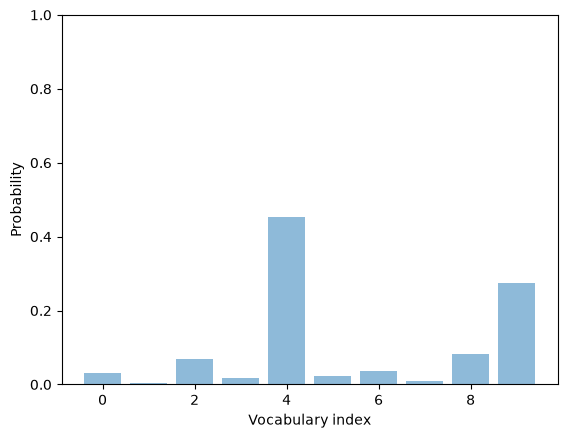

In [10]:
import matplotlib.pyplot as plt

toy_logits = torch.tensor(  #1
    [-0.7, -3.0, 0.1, -1.2, 2.0, -1.0, -0.5, -2.0, 0.3, 1.5]
)

toy_logits_scaled = scale_logits_by_temperature(toy_logits, 1.0)  #2
toy_probas = torch.softmax(toy_logits_scaled, dim=-1)   #3

plt.bar(  #4
    torch.arange(len(toy_probas)), toy_probas,
    alpha=0.5
)

plt.ylim([0, 1])
plt.xlabel("Vocabulary index")
plt.ylabel("Probability")
plt.show()

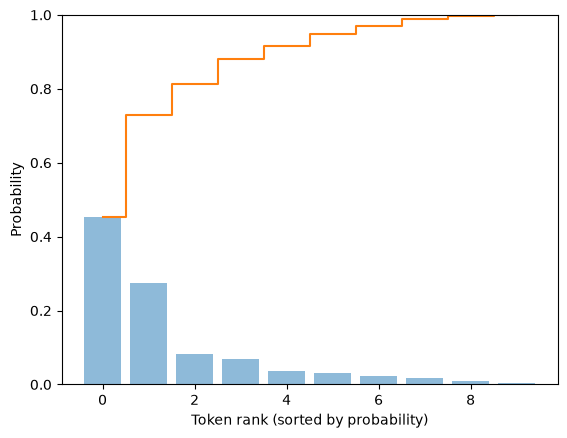

In [11]:
sorted_probas, sorted_idx = torch.sort(toy_probas, descending=True)  #1
cumsum = torch.cumsum(sorted_probas, dim=-1)  #2

plt.bar(
    torch.arange(len(sorted_probas)), sorted_probas, 
        alpha=0.5
)
plt.step(
    torch.arange(len(cumsum)), cumsum, 
    where="mid", color="C1", label="Cumulative sum"
)

plt.ylim([0, 1])
plt.xlabel("Token rank (sorted by probability)")
plt.ylabel("Probability")
plt.show()

In [12]:
# A simple-top-p filtering rule
top_p = 0.8
keep_mask = cumsum <= top_p
n_kept = torch.sum(keep_mask).item()
print("Cumulative sum:", cumsum)
print("Tokens kept:", n_kept)

Cumulative sum: tensor([0.4538, 0.7290, 0.8119, 0.8798, 0.9170, 0.9475, 0.9701, 0.9886, 0.9969,
        1.0000])
Tokens kept: 2


In [13]:
# A common top-p filtering variant
keep_mask = (cumsum - sorted_probas) < top_p
n_kept = keep_mask.sum().item()
print("Tokens kept:", n_kept)

Tokens kept: 3


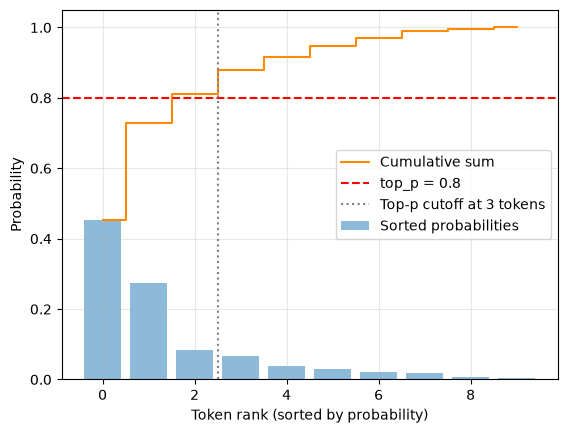

In [14]:
plt.bar(
    torch.arange(len(sorted_probas)), sorted_probas, 
    alpha=0.5, label="Sorted probabilities"
)
plt.step(
    torch.arange(len(cumsum)), cumsum, where="mid",
    color="darkorange", label="Cumulative sum"
)

plt.axhline(#1
    top_p, color="red", linestyle="--",
    label=f"top_p = {top_p}"
)
plt.axvline(
    n_kept - 0.5, color="gray", linestyle=":",
    label=f"Top-p cutoff at {n_kept} tokens"
)

plt.xlabel("Token rank (sorted by probability)")
plt.ylabel("Probability")
plt.legend()
plt.grid(alpha=0.3)
plt.ylim(0, 1.05)
plt.show()

In [15]:
# Applying top-p filtering
kept_sorted = torch.where(
    keep_mask, sorted_probas,
    torch.zeros_like(sorted_probas)
)
filtered = torch.zeros_like(toy_probas).scatter(0, sorted_idx, kept_sorted)
print(filtered)

tensor([0.0000, 0.0000, 0.0000, 0.0000, 0.4538, 0.0000, 0.0000, 0.0000, 0.0829,
        0.2752])


In [16]:
# Finally, we renormalize these values so that they sum to one again
denom = torch.sum(filtered).clamp_min(1e-12)
renormalized = filtered / denom
print(renormalized)

tensor([0.0000, 0.0000, 0.0000, 0.0000, 0.5589, 0.0000, 0.0000, 0.0000, 0.1021,
        0.3390])


In [17]:
def top_p_filter(probas, top_p):
    if top_p is None or top_p >= 1.0:
        return probas

    sorted_probas, sorted_idx = torch.sort(probas, dim=1, descending=True) #1
    cumprobas = torch.cumsum(sorted_probas, dim=1)  #2

    prefix = cumprobas - sorted_probas  #3
    keep = prefix < top_p                # Keep tokens where prefix cumulative mass (before each token) is < top_p
    keep[:, 0] = True  # For top_p <= 0, only the highest-probability token is guaranteed to be kept as a fallback

    kept_sorted = torch.where(          # Zero out beyond cutoff
        keep, sorted_probas,             # Zero out beyond cutoff
        torch.zeros_like(sorted_probas)  # Zero out beyond cutoff
    )

    filtered = torch.zeros_like(probas).scatter(1, sorted_idx, kept_sorted) # Map back to original order

    denom = torch.sum(filtered, dim=1, keepdim=True).clamp_min(1e-12) # Renormalize to sum to 1
    return filtered / denom

In [18]:
@torch.inference_mode()
def generate_text_top_p_stream_cache(
    model,
    token_ids,
    max_new_tokens,
    eos_token_id=None,
    temperature=0.,
    top_p=None
):
    model.eval()
    cache = KVCache(n_layers=model.cfg["n_layers"])
    model.reset_kv_cache()

    out = model(token_ids, cache=cache)[:, -1]  #1
    for _ in range(max_new_tokens):

        orig_device = token_ids.device

        if temperature is None or temperature == 0.0:
            next_token = torch.argmax(out, dim=-1, keepdim=True)

        else:
            logits = scale_logits_by_temperature(out, temperature)  #2
            probas = torch.softmax(logits, dim=-1)  #3

            probas = top_p_filter(probas, top_p)  #4

            next_token = torch.multinomial(probas.cpu(), num_samples=1) #5
            next_token = next_token.to(orig_device)

        if (eos_token_id is not None
                and torch.all(next_token == eos_token_id)):
            break

        yield next_token
        out = model(next_token, cache=cache)[:, -1]

In [23]:
torch.manual_seed(123)
response = generate_text_stream_concat_flex(
    model, tokenizer, prompt, device,
    max_new_tokens=2048, verbose=True,
    generate_func=generate_text_top_p_stream_cache,
    temperature=1,
    top_p=0.85, 
)

 \boxed{18}

To solve for \( x \) in the equation:

\[
\frac{1}{2} (3x - 9) = x + 37
\]

**Step 1: Eliminate the fraction by multiplying both sides by 2.**

\[
2 \times \frac{1}{2} (3x - 9) = 2 \times (x + 37)
\]

\[
3x - 9 = 2x + 74
\]

**Step 2: Subtract \( 2x \) from both sides to gather like terms.**

\[
3x - 2x - 9 = 74
\]

\[
x - 9 = 74
\]

**Step 3: Add 9 to both sides to solve for \( x \).**

\[
x = 74 + 9
\]

\[
x = 83
\]

However, let's double-check the steps to ensure accuracy.

**Revisiting Step 2:**

\[
3x - 9 = 2x + 74
\]

Subtract \( 2x \) from both sides:

\[
3x - 2x - 9 = 74
\]

\[
x - 9 = 74
\]

Add 9 to both sides:

\[
x = 83
\]

But let's verify this solution by substituting \( x = 83 \) back into the original equation.

**Original Equation:**

\[
\frac{1}{2} (3x - 9) = x + 37
\]

Substitute \( x = 83 \):

\[
\frac{1}{2} (3 \times 83 - 9) = 83 + 37
\]

\[
\frac{1}{2} (249 - 9) = 120
\]

\[
\frac{1}{2} \times 240 = 120
\]

\[
120 = 120
\]

The equation holds true, co

In [24]:
from collections import Counter
from reasoning_from_scratch.ch03 import extract_final_candidate


def self_consistency_vote(
    model, tokenizer, prompt, device,
    num_samples=10, temperature=0.8, top_p=0.9, max_new_tokens=2048,
    show_progress=True, show_long_answer=False, seed=None,
):
    full_answers, short_answers = [], []

    for i in range(num_samples):  #1
        if seed is not None:
            torch.manual_seed(seed + i + 1)

        answer = generate_text_stream_concat_flex(
            model=model, tokenizer=tokenizer, prompt=prompt, device=device,
            max_new_tokens=max_new_tokens, verbose=show_long_answer,
            generate_func=generate_text_top_p_stream_cache,
            temperature=temperature, top_p=top_p,
        )

        short = extract_final_candidate(           #2
            answer, fallback="number_then_full"     #2
        )                                           #2
        full_answers.append(answer)
        short_answers.append(short)
        if show_progress:
            print(f"[Sample {i+1}/{num_samples}] → {short!r}")

    counts = Counter(short_answers)
    groups = {s: [] for s in counts}
    for idx, s in enumerate(short_answers):
        groups[s].append(idx)

    mc = counts.most_common()  #3
    if not mc:
        majority_winners, final_answer = [], None
    else:
        top_freq = mc[0][1]
        majority_winners = [s for s, f in mc if f == top_freq]
        final_answer = mc[0][0] if len(majority_winners) == 1 else None

    return {
        "full_answers": full_answers,
        "short_answers": short_answers,
        "counts": dict(counts),
        "groups": groups,
        "majority_winners": majority_winners,
        "final_answer": final_answer,
    }

In [26]:
results = self_consistency_vote(
    model,
    tokenizer,
    prompt,
    device=device,
    num_samples=5,
    temperature=0.8,
    top_p=0.9,
    max_new_tokens=2048,
    seed=123,
    show_progress=True,
)

print(results["full_answers"][0])

[Sample 1/5] → '83'
[Sample 2/5] → '22'
[Sample 3/5] → '54'
[Sample 4/5] → '44'
[Sample 5/5] → '66'
 To find the value of \( x \), let's solve the equation step by step.

1. **Given Equation:**
   \[
   \text{Half the value of } 3x - 9 \text{ is } x + 37.
   \]
   This can be written as:
   \[
   \frac{1}{2}(3x - 9) = x + 37.
   \]

2. **Multiply Both Sides by 2 to Eliminate the Fraction:**
   \[
   2 \times \frac{1}{2}(3x - 9) = 2 \times (x + 37).
   \]
   Simplifying both sides:
   \[
   3x - 9 = 2x + 74.
   \]

3. **Subtract \( 2x \) from Both Sides to Get the \( x \)-terms on One Side:**
   \[
   3x - 2x - 9 = 74.
   \]
   Simplifying:
   \[
   x - 9 = 74.
   \]

4. **Add 9 to Both Sides to Solve for \( x \):**
   \[
   x - 9 + 9 = 74 + 9.
   \]
   Simplifying:
   \[
   x = 83.
   \]

**Final Answer:**
\[
\boxed{83}
\]


In [27]:
results = self_consistency_vote(
    model,
    tokenizer,
    prompt + "\n\nExplain step by step.",
    device=device,
    num_samples=5,
    temperature=0.8,
    top_p=0.9,
    max_new_tokens=2048,
    seed=123,
    show_progress=True,
)

[Sample 1/5] → '83'
[Sample 2/5] → '83'
[Sample 3/5] → '83'
[Sample 4/5] → '83'
[Sample 5/5] → '83'
